In [1]:
import find as fnd
import configs as cfg
import createconfig as cc
import photplotlib as pplib
import check as chk
from importlib import reload
reload(fnd)
reload(cfg)
reload(cc)
reload(pplib)
reload(chk)
from photplotlib import PhotometryPipeline, LightCurvePlotter

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [2]:
# Set the directory containing the image folders and the filt
core = '/Users/nhaurber/Downloads/2026-09-02_KnoxScope/PT/calibrated/' # parent directory where images are and light curves will be saved
LK_PATH = core #+ 'lightcurves/' # path where light curves should save inside parent directory
images_location = core #+ 'Gaia1238/'
observer = 'NH' # initials; they will be saved in file names
DATE = '2026-09-02' # date of observation

#config_file = core + 'Gaia1238/Gaia_1238_config.ini' # path to config file for target inside parent directory

# plot phased? show comparison stars?
phased = False
comps = True

# Set the gain and read noise
RDNOISE = 1.7
GAIN = 1.76

# Set the starting aperture and annulus radii
AP_R = 15
AN_I = 25
AN_O = 30

non_sid = False

winer_loc = {'lon': -110-36/60-6.42/3600, 'lat': 31+39/60+56.08/3600, 'elevation': 1515.7}

In [3]:
# ---- USER INPUTS FOR PHOTOMETRY ----
TARGET = "PT Per"
PERIOD = 0
IS_PHASE = False
PHASE_ZERO = 0
REF_IMAGE_NAME = '//Users/nhaurber/Data/PCEB/DECVn 2026-03-35/cwl_DE_CVn_g_15s_2026-03-25T03-43-13_calibrated.fts.fz'
config_output = "/Users/nhaurber/Data/PCEB/DECVn 2026-03-35/"

# ---- REF STAR FINDING SETTINGS ----
N_STARS = 5
EDGE_BUFFER = 100
SAT_LIMIT = 35000
AP_R = 8
MIN_SEP_TARGET = 30

In [4]:
### Find the target and comparison stars, and write the config file
###
### Find the target in the reference image and get its RA and Dec
src, target_ra, target_dec = cc.find_target(TARGET)
### This is the juicy step that finds the reference stars and writes the config file. It also queries VSX for known variable stars in the field.
### Small changes to createconfig.py can be made to change which stars are being selected as reference stars. The config file is written to the output directory specified in the config_output variable.
comp_stars = cc.find_comparison_stars(target_ra, target_dec, src, REF_IMAGE_NAME, N_STARS, EDGE_BUFFER, MIN_SEP_TARGET, AP_R, SAT_LIMIT)
config_path = cc.write_config(comp_stars, TARGET, PERIOD, IS_PHASE, PHASE_ZERO, REF_IMAGE_NAME, config_output)

# Because this is self contained, we can also read the config file back in and get the reference star coordinates for plotting.


DALServiceError: Unable to access the capabilities endpoint at:
- https://simbad.cds.unistra.fr/simbad/sim-tap/capabilities: 404 Not Found
- https://simbad.cds.unistra.fr/simbad/capabilities: 404 Not Found

This could mean:
1. The service URL is incorrect
2. The service is temporarily unavailable
3. The service doesn't support this protocol
4. If a 503 was encountered, retry after the suggested delay.


In [135]:
config_data = cfg.load_config(config_path, DATE)

Config file read.


In [136]:
# Read in filters from headers
# FILTERS = fnd.find_filts_fast(images_location)
# print("Filters:")
# print(FILTERS)
FILTERS = 'g'

# Find exposure time (reads from first image)
expt = str(fnd.find_exp(images_location)) + 's'
print("Exposure time: " + expt)

TITLE = config_data['TITLE'] + "_" + expt

Exposure time: 90.0s


40.71332734049931
Target PT_Per (40.71332734049931 deg, 56.691952999217484 deg)

Found 132 variable stars within 20.0 arcmin of PT_Per
RA, DEC coordinates of check stars:
(40.83023595774246, 56.628735542748764),
(40.791391305983375, 56.58371378698266),
(40.98121509415697, 56.839316474769696),
(40.83689683622061, 56.56103140642327),
(41.0402073491384, 56.66720738813648)
Reference stars in green. Variable stars in magenta. Target in red.


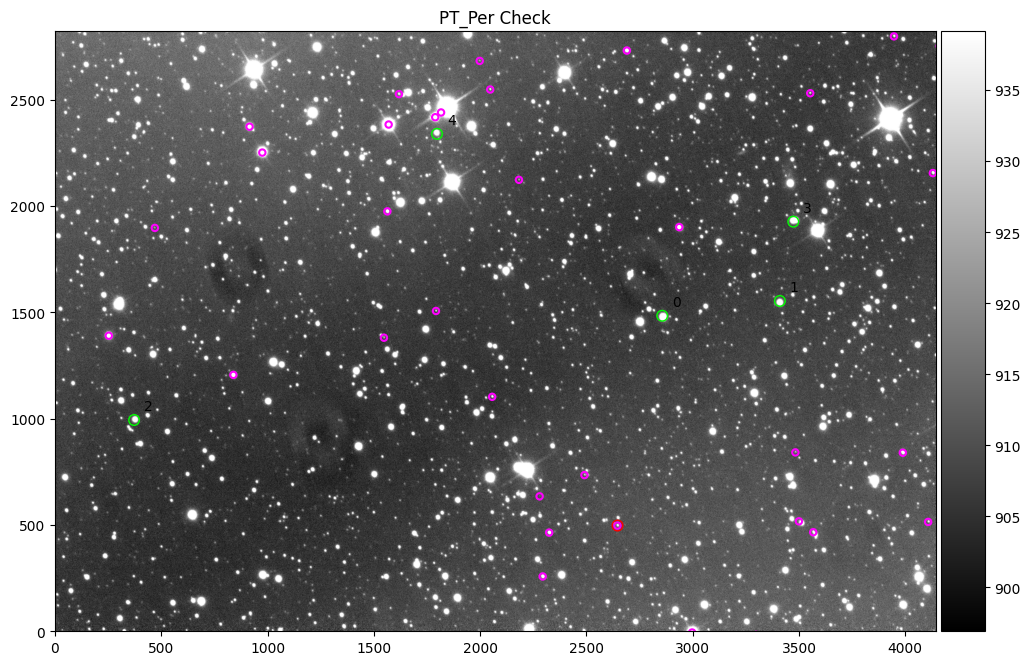

In [137]:
## ---- CHECK REFERENCE IMAGE ----
## Find the RA and Dec of the target and the source image data and search for variable stars in the region. This is done to check that the target and reference stars are correct and to plot the reference image with the target, reference stars, and variable stars marked.
target_ra, target_dec, src, vars, vsx_table = chk.get_target_coordinates(config_data['TARGET_NAME'], config_data['REFERENCE_IMAGE'])
## Convert the reference star pixel coordinates to RA and Dec for plotting and moving between frames
checkstars_radec = chk.stars_to_radec(config_data['STAR_COORDS'], config_data['REFERENCE_IMAGE'])
## Plot the reference image with the target, reference stars, and variable stars marked
chk.plot_reference_image(config_data['TARGET_NAME'], target_ra, target_dec, config_data['REFERENCE_IMAGE'], checkstars_radec, vsx_table, show_ref_stars=True, show_var_stars=True)


In [138]:
pipe = PhotometryPipeline(
    file_dir=images_location,
    star_list_pix=config_data['STAR_COORDS'],
    ref_image=config_data['REFERENCE_IMAGE'],
    target_name=config_data['TARGET_NAME'],
    rdnoise=RDNOISE,
    aperture_radius=AP_R,
    annulus_inner=AN_I,
    annulus_outer=AN_O,
    gain=GAIN
)

# Loop over the filters and perform the photometry
for filt in FILTERS:
    print('Performing photometry for filter:', filt)
    pipe.perform_var_fwhm_phot(filt, 
                               save_ref_star_coords=False, display_apertures=False, save=True, 
                               plot=True, errorshow=True, title=config_data['TITLE'], non_sidereal=non_sid)
    pipe.calc_ap_ratio(filt, 
                       larger_ap=18, mean=True, median=False, title = config_data['TITLE'])
    
    pipe.find_mags(filt, 
                   save=True, save_ref_star_coords=False, display_apertures=False, title = config_data['TITLE'])
    
    LightCurvePlotter.plot_relative(file_dir=images_location, 
                                    filt=filt, title = config_data['TITLE'], phase=phased, comp_stars=comps, 
                                    phase_zero=config_data['PHASE_ZERO'], period=config_data['PERIOD'], save_path=LK_PATH, errorshow=True)
    
    LightCurvePlotter.plot_absolute(file_dir=images_location, 
                                    title = config_data['TITLE'], filt=filt, phase=phased, 
                                    phase_zero=config_data['PHASE_ZERO'], period=config_data['PERIOD'])

Performing photometry for filter: g
Target Name: PT_Per
Target RA: 40.71332767271119
Target Dec: 56.691951998807
RA/Dec of all stars: [(np.float64(40.71332767271119), np.float64(56.691951998807)), [array(40.83023596), array(56.62873554)], [array(40.79139131), array(56.58371379)], [array(40.98121509), array(56.83931647)], [array(40.83689684), array(56.56103141)], [array(41.04020735), array(56.66720739)]]
obstime: 2026-09-03T05:12:16
  star 4, pos=(3580.5,1949.0), ap_sum=1142573.0, bkg_mean=909.7, bkg_sum=1143151.3, gain=1.76
Skipping /Users/nhaurber/Downloads/2026-09-02_KnoxScope/PT/calibrated/GCVS_PT_PER_g_stacked.fits due to negative , image should be inspected.


KeyError: 'star_1_flux'